# Exercise 55 – Softmax and cross-entropy

**Week 11 · Classification**

For classification with $K$ classes a network outputs $K$ numbers (*logits*).
The softmax function turns them into probabilities,

$$Q(k\,|\,x) = \frac{e^{z_k}}{\sum_{k'} e^{z_{k'}}},$$

and the cross-entropy $H = -\frac{1}{N}\sum_i \log Q(y_i\,|\,x_i)$ measures
how surprised the model is by the true labels $y_i$. Here we take a fixed
linear model $\mathbb{R} \to \mathbb{R}^3$ and explore these quantities.

In [1]:
import matplotlib.pyplot as plt
import torch
from torch import nn

from comphy.plotting import setup_axes

torch.manual_seed(0)

model = nn.Linear(1, 3)
with torch.no_grad():
    model.weight[:] = torch.tensor([[0.7], [0.25], [0.9]])
    model.bias[:] = torch.tensor([1.0, -0.4, 0.5])

x_test = torch.linspace(-6, 6, 7).reshape(-1, 1)
logits = model(x_test).detach()
print("x:", x_test.flatten().tolist())
print("logits:\n", logits)

x: [-6.0, -4.0, -2.0, 0.0, 2.0, 4.0, 6.0]
logits:
 tensor([[-3.2000, -1.9000, -4.9000],
        [-1.8000, -1.4000, -3.1000],
        [-0.4000, -0.9000, -1.3000],
        [ 1.0000, -0.4000,  0.5000],
        [ 2.4000,  0.1000,  2.3000],
        [ 3.8000,  0.6000,  4.1000],
        [ 5.2000,  1.1000,  5.9000]])


## Softmax by hand and with PyTorch

In [2]:
def softmax(z):
    return torch.exp(z) / torch.exp(z).sum(dim=1, keepdim=True)


probabilities = softmax(logits)
print(probabilities)
print("identical to torch.softmax:", torch.allclose(probabilities, torch.softmax(logits, dim=1)))

tensor([[0.2061, 0.7562, 0.0377],
        [0.3617, 0.5397, 0.0986],
        [0.4967, 0.3013, 0.2020],
        [0.5396, 0.1331, 0.3273],
        [0.4987, 0.0500, 0.4513],
        [0.4183, 0.0171, 0.5646],
        [0.3300, 0.0055, 0.6645]])
identical to torch.softmax: True


## Cross-entropy of guessed labels

Which labelling of the seven test points is the model least surprised by?
Trying 10 000 random labellings and keeping the one with the smallest
cross-entropy recovers the *most probable* class of each point – exactly what
`argmax` gives directly.

In [3]:
def cross_entropy(probabilities, labels):
    return -torch.log(probabilities[torch.arange(len(labels)), labels]).mean()


best_h, best_labels = float("inf"), None
for _ in range(10_000):
    guess = torch.randint(0, 3, (len(x_test),))
    h = cross_entropy(probabilities, guess)
    if h < best_h:
        best_h, best_labels = h.item(), guess

print(f"best random guess: {best_labels.tolist()}  H = {best_h:.4f}")
print(f"argmax labels    : {probabilities.argmax(dim=1).tolist()}")
print(f"torch CrossEntropyLoss on the logits: "
      f"{nn.CrossEntropyLoss()(logits, probabilities.argmax(dim=1)):.4f}")

best random guess: [1, 1, 0, 0, 0, 2, 2]  H = 0.5555
argmax labels    : [1, 1, 0, 0, 0, 2, 2]
torch CrossEntropyLoss on the logits: 0.5555


Note that `nn.CrossEntropyLoss` takes the raw logits and applies the softmax
internally.

## Class probabilities as a function of x

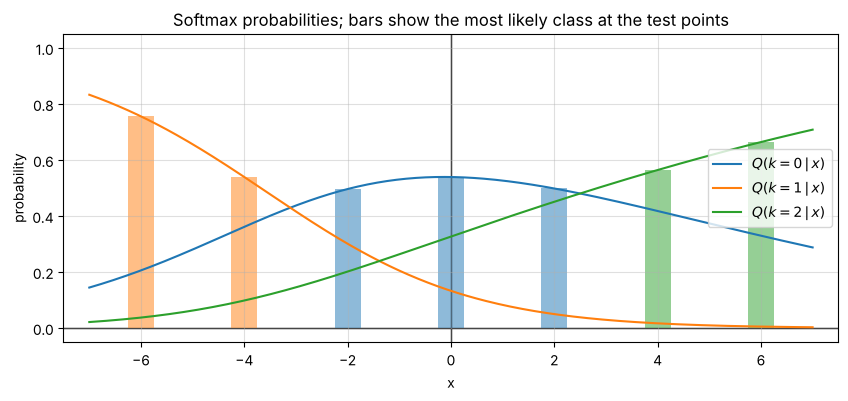

In [4]:
xs = torch.linspace(-7, 7, 300).reshape(-1, 1)
q = torch.softmax(model(xs), dim=1).detach()
labels = probabilities.argmax(dim=1)

fig, ax = plt.subplots(figsize=(10, 4))
for k in range(3):
    ax.plot(xs, q[:, k], color=f"C{k}", label=f"$Q(k={k}\\,|\\,x)$")
for x, p, k in zip(x_test.flatten(), probabilities, labels):
    ax.bar(x, p[k], width=0.5, color=f"C{k}", alpha=0.5)
setup_axes(ax, xlim=(-7.5, 7.5), ylim=(-0.05, 1.05), ylabel="probability",
           title="Softmax probabilities; bars show the most likely class at the test points")
ax.legend(loc="center right")
plt.show()

## Applying the model to data
300 points drawn from three Gaussians are labelled by the model's most
probable class.

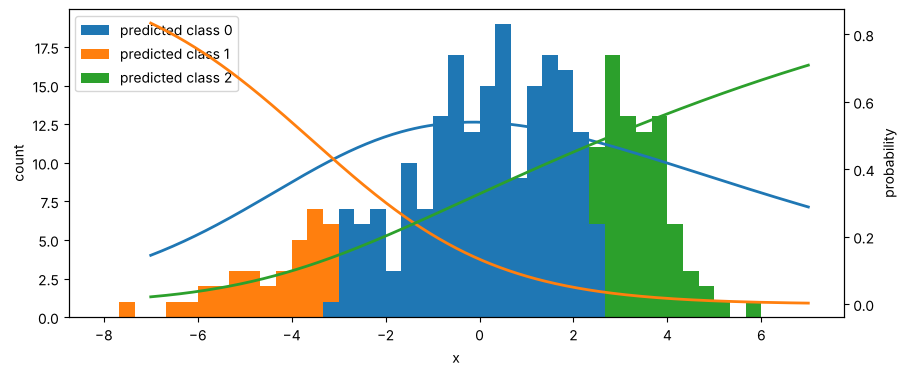

In [5]:
data = torch.cat([torch.normal(-2.0, 2.0, (100,)), torch.normal(0.5, 1.0, (100,)),
                  torch.normal(3.0, 1.0, (100,))]).reshape(-1, 1)
predicted = model(data).argmax(dim=1)

fig, ax = plt.subplots(figsize=(10, 4))
bins = torch.linspace(-8, 7, 46)
ax.hist([data[predicted == k].flatten().numpy() for k in range(3)], bins=bins.numpy(),
        stacked=True, color=["C0", "C1", "C2"], label=[f"predicted class {k}" for k in range(3)])
ax2 = ax.twinx()
for k in range(3):
    ax2.plot(xs, q[:, k], color=f"C{k}", lw=2)
ax2.set_ylabel("probability")
ax.set(xlabel="x", ylabel="count")
ax.legend(loc="upper left")
plt.show()